# 410 – Quantum Neural Network Classifier with `EstimatorQNN`

A **quantum neural network (QNN)** is a parameterised circuit used like a layer of a neural
network: classical *inputs* go in through a **feature map**, trainable *weights* sit in an
**ansatz**, and a measured number comes out.  In this notebook the output is an
**expectation value**, computed with Qiskit's *Estimator* primitive.

> **Name change.** Older Qiskit versions called this model `OpflowQNN` / `TwoLayerQNN`.
> Opflow was removed in Qiskit 1.0; `EstimatorQNN` is its replacement.

**Where this fits:** after `403` (a classifier built by hand) you now let
`qiskit-machine-learning` do the plumbing.  Notebooks `410`–`412` solve the *same* problem
with three different model types:

| Notebook | Model | Network output | Labels |
|---|---|---|---|
| `410` | `EstimatorQNN` + `NeuralNetworkClassifier` | expectation value $\langle Z\otimes Z\rangle \in [-1, 1]$ | $-1$ / $+1$ |
| `411` | `SamplerQNN` + `NeuralNetworkClassifier` | probabilities of the 2 classes (via parity of the bitstring) | $0$ / $1$ |
| `412` | `VQC` (all-in-one) | class probabilities | one-hot |

**You will learn to** build an `EstimatorQNN` from a feature map and an ansatz, run its
forward and backward pass, and train it with `NeuralNetworkClassifier`.

**Prerequisites:** `008-03` (Estimator primitive), `101` (variational forms), `403`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier

algorithm_globals.random_seed = 42

## Primitives

*Primitives* are Qiskit's standard way to run circuits: the **Estimator** returns expectation
values of observables, the **Sampler** returns measured bitstrings.  The `Statevector`
versions simulate exactly on your computer; on real hardware you would pass the IBM Runtime
primitives instead – the rest of the code stays the same.

In [3]:
# primitives replace the old QuantumInstance
estimator = StatevectorEstimator()
sampler = StatevectorSampler(default_shots=1024)

## The dataset

20 random points in the square $[-1, 1]^2$.  A point belongs to class **+1** (blue) if
$x_0 + x_1 \ge 0$ and to class **−1** (green) otherwise – the two classes are separated by the
dashed diagonal.  The same data (same seed) is used in `410`, `411` and `412`, so you can compare
the three models directly.  Three label formats are prepared: `y` ($\pm 1$), `y01` ($0/1$) and
`y_one_hot`.

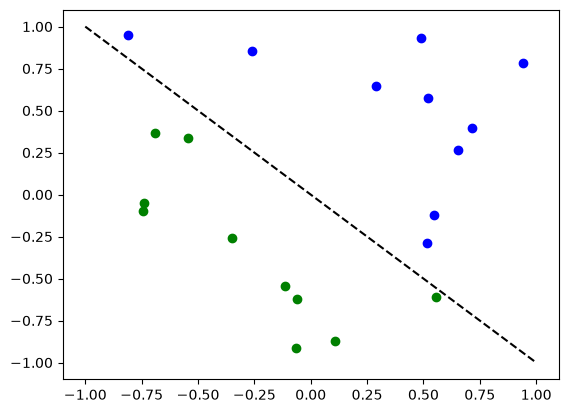

In [4]:
num_inputs = 2
num_samples = 20
X = 2 * algorithm_globals.random.random([num_samples, num_inputs]) - 1
y01 = 1 * (np.sum(X, axis=1) >= 0)  # in { 0,  1}
y = 2 * y01 - 1  # in {-1, +1}
y_one_hot = np.zeros((num_samples, 2))
for i in range(num_samples):
    y_one_hot[i, y01[i]] = 1

for x, y_target in zip(X, y):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

## Building the QNN

* **Feature map** `zz_feature_map(2)` – loads the two input values $x_0, x_1$ into rotation
  angles (with $ZZ$ interactions between the qubits).  Its parameters are the **inputs**.
* **Ansatz** `real_amplitudes(2)` – layers of $R_Y$ rotations and CNOTs.  Its parameters are
  the trainable **weights**.
* **Observable** – by default $Z\otimes Z$ (the *parity* of the two qubits), so the network
  output is a number in $[-1, 1]$; its sign is the predicted class.

inputs : 2  weights: 8


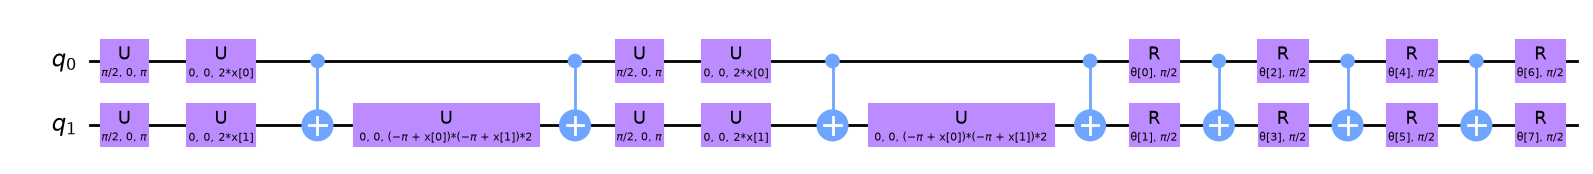

In [5]:
feature_map = zz_feature_map(num_inputs)
ansatz = real_amplitudes(num_inputs)

qnn_circuit = QuantumCircuit(num_inputs)
qnn_circuit.compose(feature_map, inplace=True)
qnn_circuit.compose(ansatz, inplace=True)

estimator_qnn = EstimatorQNN(circuit=qnn_circuit, input_params=feature_map.parameters,
                             weight_params=ansatz.parameters, estimator=estimator)
print("inputs :", estimator_qnn.num_inputs, " weights:", estimator_qnn.num_weights)
qnn_circuit.decompose().draw(output="mpl", style="clifford")

### Forward and backward pass

Like any neural-network layer, a QNN has a **forward** pass (inputs + weights → output) and a
**backward** pass (gradients of the output with respect to inputs and weights).  The gradients
are computed with the *parameter-shift rule* – i.e. by running extra circuits, the same idea
as the Hadamard-test gradients in `403`.

In [6]:
weights = algorithm_globals.random.random(estimator_qnn.num_weights)

output = estimator_qnn.forward(X[0, :], weights)
print("forward  – output for the first sample:", output)

input_grad, weight_grad = estimator_qnn.backward(X[0, :], weights)
print("backward – gradient w.r.t. the weights has shape", weight_grad.shape,
      "(samples, outputs, weights)")

forward  – output for the first sample: [[0.2318079]]
backward – gradient w.r.t. the weights has shape (1, 1, 8) (samples, outputs, weights)


## Training

`qiskit-machine-learning` classifiers follow the **scikit-learn** interface: `fit`, `predict`,
`score`.  Training is a classical optimisation of the circuit weights; here we use **COBYLA**,
a gradient-free optimiser that works well for a handful of parameters.

The callback below redraws the objective (loss) after every optimiser step, so you can watch the
training happen.

In [7]:
# callback function that draws a live plot when the .fit() method is called
def callback_graph(weights, obj_func_eval):
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

In [8]:
# construct neural network classifier
estimator_classifier = NeuralNetworkClassifier(estimator_qnn, optimizer=COBYLA(), callback=callback_graph)

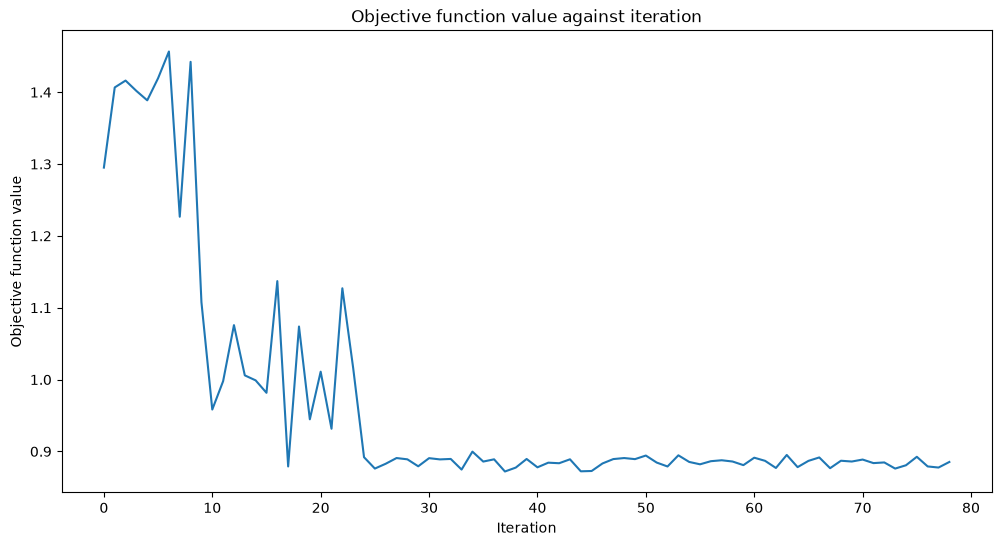

accuracy on the training data: 0.75


In [9]:
# create empty array for callback to store evaluations of the objective function
objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)

# fit classifier to data
estimator_classifier.fit(X, y)

# return to default figsize
plt.rcParams["figure.figsize"] = (6, 4)

# score classifier
print("accuracy on the training data:", estimator_classifier.score(X, y))

## Evaluating the result

Blue / green dots are the two classes; a **red circle** marks a point the trained model gets
wrong.  `score` is the accuracy on the given data.

Don't expect 100 % here.  The ZZ feature map bends the data in a complicated way that does not
suit a straight-line boundary, and COBYLA stops after a fixed budget of steps.  Accuracies of
roughly 65–85 % are typical for this example (exercises 1–2 explore why).

> We score on the *training* data to keep the example short.  A fair evaluation needs separate
> test data – see `413` and `415`, and exercise 3 below.

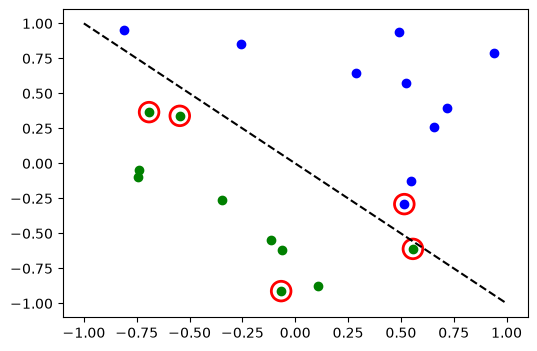

In [10]:
# evaluate data points
y_predict = estimator_classifier.predict(X)

# plot results
# red == wrongly classified
for x, y_target, y_p in zip(X, y, y_predict):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
    if y_target != y_p:
        plt.scatter(x[0], x[1], s=200, facecolors="none", edgecolors="r", linewidths=2)
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

## Key takeaways
* A QNN = **feature map** (inputs) + **ansatz** (weights) + **measurement**.
* `EstimatorQNN` returns expectation values – one real number per observable.
* `NeuralNetworkClassifier` wraps any QNN in a scikit-learn style `fit` / `predict` / `score`.

## Try it yourself
1. Use `real_amplitudes(num_inputs, reps=1)` instead of the default 3 repetitions.  Fewer
   weights – does it still learn the diagonal?
2. Swap COBYLA for `L_BFGS_B` (from `qiskit_machine_learning.optimizers`), which *uses* the
   gradients of the backward pass.  Compare the number of iterations.
3. Generate 20 *new* points the same way and compute the accuracy on them (a test set).
4. Make the problem harder: label points by $x_0 \cdot x_1 \ge 0$ (a checkerboard).  What happens?

**Next:** `411-QNN-Classifier-SamplerQNN` – the same task with a sampler-based QNN.